In [4]:
# Import libraries
import cv2
import numpy as np
import matplotlib.pyplot as plt

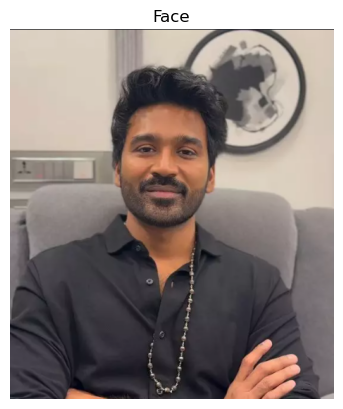

(526, 460, 3)


In [5]:
# Load the Face Image
faceImage = cv2. imread('dhanushpic.png')

plt.imshow(faceImage[:, :, ::- 1])
plt.title("Face")
plt.axis('off')
plt. show()

print ( faceImage.shape)

In [7]:
faceImage.shape

(526, 460, 3)

In [6]:
#resized_faceImage.shape
faceImage.shape

(526, 460, 3)

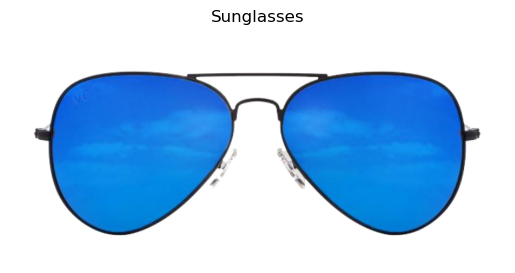

(350, 745, 4)


In [8]:

# Load the Sunglass image with Alpha channel
# (http://pluspng.com/sunglass-png-1104.html)
glassImg = cv2. imread('blueglass.png', cv2. IMREAD_UNCHANGED)

# Extract the color channels
glassBGR = glassImg[:, :,:3]

plt.imshow(glassBGR[:, :, ::- 1])
plt.title("Sunglasses")
plt.axis('off')
plt.show()

print(glassImg.shape)

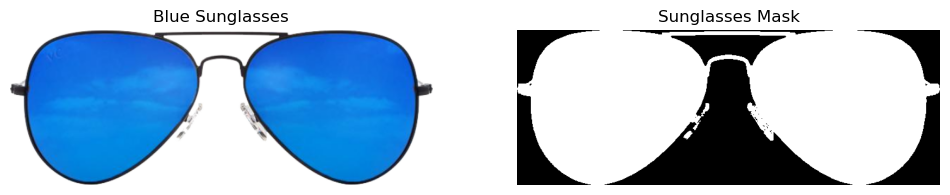

In [9]:
# Extract the BGR color channels
glassBGR = glassImg[:, :, :3]

# Create the mask using grayscale
gray = cv2.cvtColor(glassBGR, cv2.COLOR_BGR2GRAY)

_, glassMask1 = cv2. threshold(
gray, 235, 255, cv2. THRESH_BINARY_INV

)

# Find the sunglasses boundaries
x, y, w, h = cv2.boundingRect(glassMask1)

# Crop the sunglasses and mask
glassBGR = glassBGR[y:y+h, x:x+w]
glassMask1 = glassMask1[y:y+h, x:x+w]

# Display the original blue sunglasses
plt.figure(figsize=(12, 5))

plt.subplot(121)
plt.imshow(cv2.cvtColor(glassBGR, cv2.COLOR_BGR2RGB))
plt.title("Blue Sunglasses")
plt.axis('off')

plt.subplot(122)
plt.imshow(glassMask1, cmap='gray')
plt.title("Sunglasses Mask")
plt.axis('off')

plt.show()

In [13]:
# Resize the sunglasses to fit the eye region
newW = int(faceImage. shape[1] * 0.40)
newH = int(glassBGR.shape[0] * newW / glassBGR.shape[1])

glassBGR = cv2.resize(
    glassBGR, (newW, newH),
    interpolation=cv2.INTER_AREA
)

glassMask1 = cv2.resize(
    glassMask1, (newW, newH),
    interpolation=cv2.INTER_NEAREST
)

print("Sunglass dimension =", glassBGR. shape)

# Position the sunglasses
faceH, faceW = faceImage. shape[ :2]

centerX = faceW // 2
centerY = int(faceH * 0.36)

x0 = max(0, min(centerX - newW // 2, faceW - newW))
y0 = max(0, min(centerY - newH // 2, faceH - newH))

x1 = x0 + newW
y1 = y0 + newH

Sunglass dimension = (67, 184, 3)


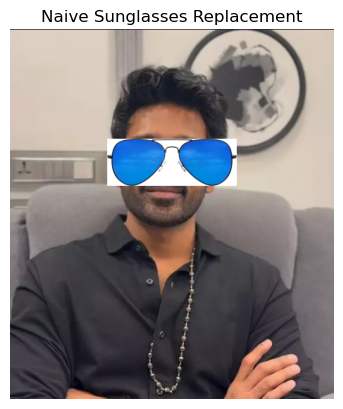

In [14]:
# Naive replacement
faceWithGlassesNaive = faceImage.copy()

faceWithGlassesNaive[y0:y1, x0:x1] = glassBGR

plt.imshow(faceWithGlassesNaive[:, :, ::- 1])
plt. title("Naive Sunglasses Replacement")
plt.axis('off')
plt.show()

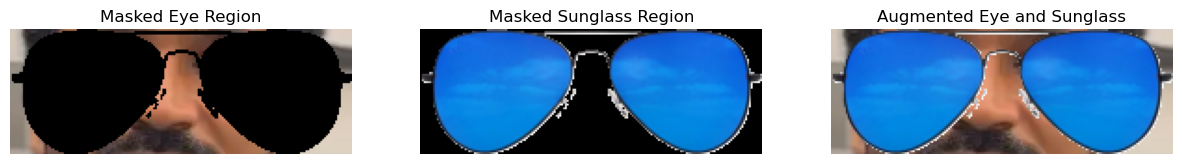

In [15]:
# Using the mask with arithmetic operations
glassMask = cv2.merge(
(glassMask1, glassMask1, glassMask1)

)

# Convert mask values to 0 and 1
glassMask = np.uint8(glassMask / 255)

# Copy the face image
faceWithGlassesArithmetic = faceImage.copy()

# Select the eye region
eyeROI = faceWithGlassesArithmetic[y0:y1, x0:x1]

# Apply arithmetic operations
maskedEye = cv2.multiply(eyeROI, 1 - glassMask)

maskedGlass = cv2.multiply(glassBGR, glassMask)

eyeRoiFinal = cv2.add(maskedEye, maskedGlass)

# Display the results
plt.figure(figsize=[15, 6])

plt.subplot(131)
plt.imshow(maskedEye[:, :, ::- 1])
plt. title("Masked Eye Region")
plt.axis('off')

plt.subplot(132)
plt.imshow(maskedGlass[:, :, ::- 1])
plt.title("Masked Sunglass Region")
plt.axis('off')

plt.subplot(133)
plt.imshow(eyeRoiFinal[:, :, ::- 1])
plt.title("Augmented Eye and Sunglass")
plt.axis('off')

plt.show()

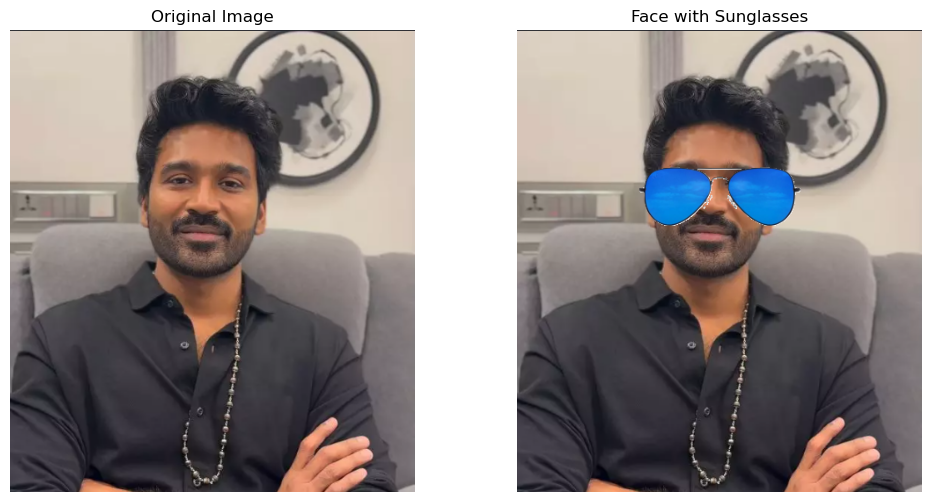

In [16]:
# Final Result
faceWithGlassesArithmetic[y0:y1, x0:x1] = eyeRoiFinal

# Display the original and final images
plt.figure(figsize=[12, 6])

plt.subplot(121)
plt.imshow(faceImage[:, :, ::- 1])
plt. title("Original Image")
plt.axis('off')

plt.subplot(122)
plt.imshow(faceWithGlassesArithmetic[:, :, ::- 1])
plt.title("Face with Sunglasses")
plt.axis('off')

plt.show()